# Joint microscopy planning with eight image settings and RUDDER

**Executed research prototype · Novelty Discovery · 22 November 2026**

This notebook contains its complete source, compact measured EELS data, trained policies, and actual comparison results. Running all cells displays the supplied study, verifies the physics, and runs a fresh held-out campaign. The final section can retrain the experiment.

**Answer to the reward question:** RUDDER's predicted final returns are sufficient. Take their successive differences and apply the terminal residual correction. These are the numerical intermediate rewards used by the policy; no additional hand-designed action reward is required.

**Finding from the completed pilot:** the three learned reward conditions have similar performance. The RF uncertainty proxy often increases while held-out prediction error falls. The reward mechanism works, but a better scientific policy has not been demonstrated.


## 1. Set up the complete project

The folded cell contains the source/data/results archive. It writes into a new local project folder. Existing project files are retained on subsequent runs.

In [1]:
import importlib.util, subprocess, sys
from pathlib import Path
missing = [dist for module, dist in [('numpy','numpy'), ('scipy','scipy'),
    ('sklearn','scikit-learn'), ('matplotlib','matplotlib'), ('pandas','pandas')]
    if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch',
                           '--index-url', 'https://download.pytorch.org/whl/cpu'])


In [2]:
#@title Restore the complete project (source, data, models, results)
import base64, hashlib, io, zipfile
payload = base64.b64decode('...')
assert hashlib.sha256(payload).hexdigest() == '93bd3409f29835921b8863dc86efaad3a3273206ed680e46fb41b8e76c489710'
PROJECT_PARENT = Path('Microscopy_RUDDER_Project').resolve()
PROJECT = PROJECT_PARENT / 'rudder_microscopy'
if not PROJECT.exists():
    PROJECT_PARENT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        for member in archive.infolist():
            target = (PROJECT_PARENT / member.filename).resolve()
            if PROJECT_PARENT not in target.parents:
                raise ValueError('Unsafe archive path')
        archive.extractall(PROJECT_PARENT)
    print('Unpacked the supplied project.')
else:
    print('Using the existing project folder; local edits are preserved.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
del payload
print(PROJECT)


Unpacked the supplied project.
/workspace/scratch/bc230469faef/notebook_validation_final/Microscopy_RUDDER_Project/rudder_microscopy


In [3]:
import json, numpy as np, pandas as pd, torch
from IPython.display import display, Image
from environment import Config, load_data, CampaignEnv, blur_sigma
from learning import (LearningConfig, load_checkpoint, collect_episode,
                      predict_and_redistribute, redistribute_rewards)
torch.set_num_threads(1)
DATA = load_data(PROJECT / 'data/eels_dataset2.npz')
STUDY = json.loads((PROJECT / 'results/study_results.json').read_text())
CFG = Config(**STUDY['manifest']['environment'])
display(pd.Series({'source': DATA.metadata['source_filename'],
    'measured image': DATA.image.shape, 'acquisition centers': len(DATA.pool_ids),
    'hidden test centers': len(DATA.test_ids), 'budget': CFG.budget,
    'initial seed pairs': CFG.seed_pairs, 'reference bank': CFG.ref_size}))


source                 Plasmonic_sets_hackathon.npy
measured image                             (33, 63)
acquisition centers                            1247
hidden test centers                             416
budget                                        100.0
initial seed pairs                               12
reference bank                                   64
dtype: object

## 2. Ten instrument actions

Eight image acquisition settings, CALIBRATE, and SPECTRUM are available. The physical drift and action history remain continuous.

For image setting $\tau$, acquisition time is $3\tau$ and scan-direction blur is

$$\sigma(\tau)=\sqrt{\max(0,(1/\tau-1)/0.12)}.$$

Calibration costs one time unit and returns the beam to the retained image's material anchor at calibration completion. It preserves the image and its blur. Spectroscopy costs one unit and uses the drift at its midpoint. All times use the original notebook's model units.


,action_id,image_setting,tau,duration,blur_sigma_pixels
0,0,1,0.2000,0.6000,5.7735
1,1,2,0.3143,0.9429,4.2640
2,2,3,0.4286,1.2857,3.3333
3,3,4,0.5429,1.6286,2.6491
4,4,5,0.6571,1.9714,2.0851
5,5,6,0.7714,2.3143,1.5713
6,6,7,0.8857,2.6571,1.0370
7,7,8,1.0000,3.0000,0.0000


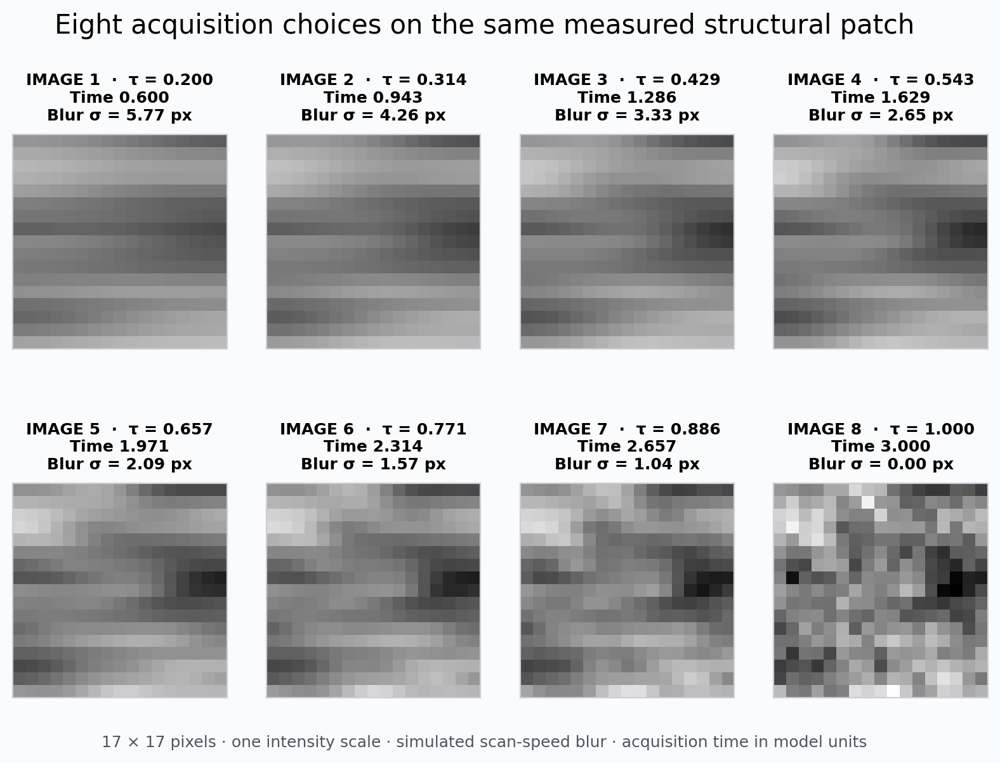

In [4]:
scan_settings = pd.DataFrame([{'action_id':i, 'image_setting':i+1,
    'tau':tau, 'duration':CFG.image_cost_factor*tau,
    'blur_sigma_pixels':blur_sigma(tau)} for i,tau in enumerate(CFG.taus)])
display(scan_settings.round(4))
display(Image(filename=str(PROJECT / 'results/figures/eight_scan_settings.png')))


## 3. Reactive registration and the final objective

Let $r_I$ be the physical object represented by the retained image, $d(t)$ the simulated continuous drift, and $t_c$ calibration completion. A spectrum starting at $t_s$ has midpoint position

$$r_S=r_I+d(t_s+T_S/2)-d(t_c).$$

Immediately after calibration, constant velocity gives residual $vT_S/2$. No Kalman model or future coordinate compensation is used. Outside-field spectroscopy consumes time and yields no new supervised pair.

The scientific learner maps 49 pooled structural features to five standardized measured spectral principal components. Its reference bank stays fixed throughout the campaign. The chosen score is

$$G=U_0-U_T,$$

where $U$ is RF tree disagreement. The forest refits after each successful spectrum and at the endpoint. Negative changes are retained. The independent held-out MSE audit is excluded from both policy and reward-predictor inputs.


In [5]:
from verify import run_verification
verification = run_verification(PROJECT / 'data/eels_dataset2.npz')
display(pd.DataFrame([{'check': c['name'], 'status': c['status']}
                     for c in verification['checks']]))
assert verification['status'] == 'pass'


,check,status
0,partitions_initialization_and_eight_blur_states,pass
1,constant_velocity_midpoints_and_reactive_regis...,pass
2,nonlinear_drift_and_physical_clock_continuity,pass
3,off_map_spectrum_does_not_create_a_pair,pass
4,hidden_test_labels_do_not_affect_learning,pass
5,physical_budget_and_signed_scientific_return,pass
6,redistribution_conservation_and_control_variat...,pass
7,causal_prefix_model_and_privileged_field_exclu...,pass


## 4. What RUDDER learns

For each causal history prefix, the GRU predicts $g_k\approx\mathbb E[G\mid h_k]$. With $g_0=0$,

$$\widetilde r_k=g_k-g_{k-1}.$$

At the final action, add $G-g_K$. Consequently, $\sum_k\widetilde r_k=G$.

These rewards are history dependent. They can be positive or negative. The first reward includes the initial prediction offset, while the last includes residual prediction error. Neither should be mistaken for a clean causal effect of that boundary action.

The predictor is fitted on previous campaigns and frozen while assigning rewards to each new on-policy batch. Whole campaigns are held out for validation. The same recurrent PPO architecture, initialization, action prior, time budget, and observations are used for terminal, direct, and RUDDER rewards.


In [6]:
import inspect
print(inspect.getsource(redistribute_rewards))


def redistribute_rewards(predictions: Sequence[float], terminal_score: float):
    """Return prediction differences and exact last-step residual in raw units.

    g_0 is defined as zero. The final correction is G - g_K. Consequently
    sum(rewards)==G (to floating-point precision), including negative rewards.
    """
    values = np.asarray(predictions, dtype=np.float64)
    if values.ndim != 1 or len(values) == 0 or not np.isfinite(values).all():
        raise ValueError("Expected a nonempty finite vector of prefix predictions")
    if not np.isfinite(terminal_score):
        raise ValueError("The terminal score must be finite")
    rewards = np.diff(np.concatenate(([0.0], values)))
    residual = float(terminal_score - values[-1])
    rewards[-1] += residual
    # Compensate only roundoff; this is not an extra learned reward.
    rewards[-1] += float(terminal_score - rewards.sum(dtype=np.float64))
    return rewards, residual



## 5. Measured comparison

The recorded pilot used 192 training campaigns and 32 shared warmups per training seed, three training seeds, and 24 unseen evaluation campaigns per trained policy. The total budget is 100 units, including 45.8 units of common initialization. Primary evaluation samples the learned stochastic policy. Deterministic deployment is reported separately.

,label,Ufinal,terminal_score,heldout_mse,n_successful_pairs,n_calibrations
0,PPO · terminal reward,0.49392,-0.03311,0.77989,6.83333,5.20833
1,PPO · direct uncertainty change,0.49471,-0.03390,0.78028,6.75000,5.23611
2,PPO · RUDDER redistribution,0.49466,-0.03385,0.78015,6.79167,5.15278
3,Fast · no calibration,0.54242,-0.08162,0.72468,23.95833,0.00000
4,Fast · calibration,0.48745,-0.02664,0.75274,17.29167,20.00000
5,Middle · no calibration,0.50929,-0.04848,0.75273,12.04167,0.00000
6,Middle · calibration,0.48777,-0.02696,0.76870,11.29167,13.00000
7,Slow · no calibration,0.49409,-0.03328,0.76263,9.54167,0.00000
8,Slow · calibration,0.47130,-0.01049,0.77451,8.50000,10.00000


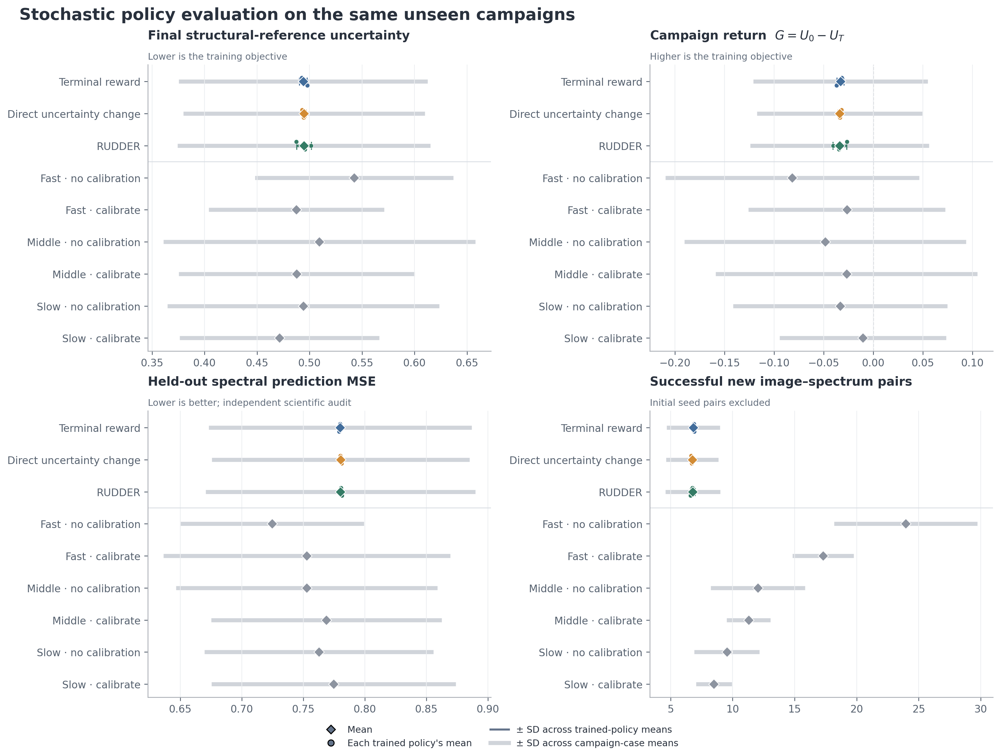

In [7]:
summary = pd.read_csv(PROJECT / 'results/project_summary.csv')
display(summary[['label','Ufinal','terminal_score','heldout_mse',
                 'n_successful_pairs','n_calibrations']].round(5))
display(Image(filename=str(PROJECT / 'results/analysis/comparison_stochastic.png')))


The three learned controllers have similar scores in this pilot. RUDDER's mean held-out MSE is **0.7802**, improving from **0.8574** initially. Nevertheless its mean RF disagreement rises from **0.4608** to **0.4947**.

This is an objective-validity issue: RF tree disagreement is not a calibrated measure of epistemic uncertainty. A controller can improve one reported quantity while worsening the other. The saved paired analysis does not establish a RUDDER policy advantage. The fixed workflows use a preferred speed with a shorter feasible fallback near the budget boundary.


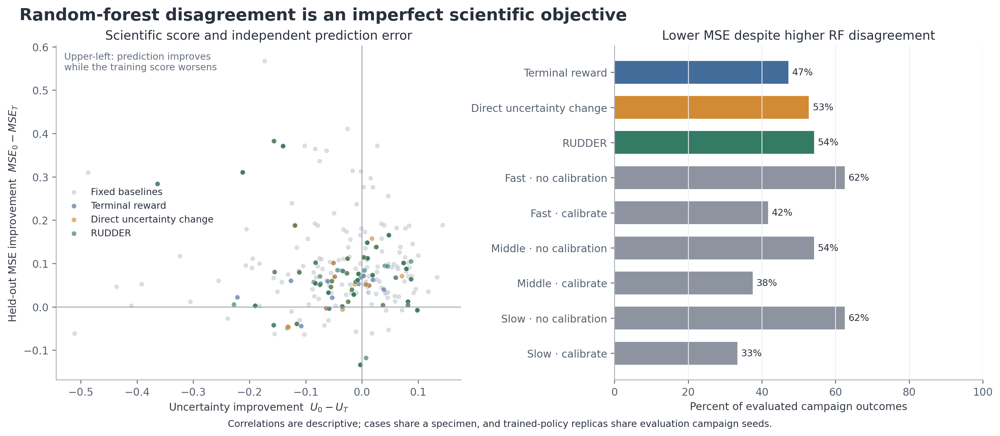

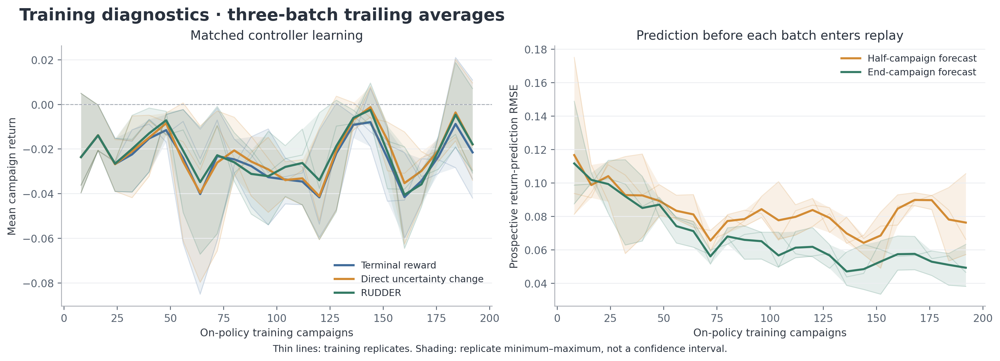

In [8]:
display(Image(filename=str(PROJECT / 'results/analysis/uncertainty_vs_error.png')))
display(Image(filename=str(PROJECT / 'results/analysis/training_curves.png')))


## 6. Inspect numerical intermediate rewards on a fresh campaign

This cell loads the saved RUDDER model from training seed 0 and runs the predetermined first linear-drift evaluation case. It is a new execution, not a replay of the stored rewards.

Across unseen evaluation campaigns, final-prefix forecast skill relative to the warmup-mean predictor averaged **0.600**. The mean absolute terminal correction was **0.0427**. Return conservation is exact to floating-point precision, but prediction and attribution remain imperfect.

A stronger baseline predicts the final return as the currently observed uncertainty gain, assuming zero further gain. RUDDER's RMSE is 0.0852 versus 0.0980 at one-quarter of the action sequence, and 0.0795 versus 0.0852 halfway through. At three-quarters it is worse: 0.0747 versus 0.0697. At termination the current gain is the actual return by definition. The supplied prefix_prediction_baselines.csv contains all individual comparisons.


Actual campaign score: -0.00321437
Sum of intermediate rewards: -0.00321437
Terminal prediction correction: -0.00101917


,step,time,action,tau,direct_delta_U,predicted_final_return,RUDDER_reward
0,1,48.457143,IMAGE,0.885714,0.000000,0.008726,0.008726
1,2,49.457143,SPECTRUM,0.885714,0.026397,0.031740,0.023014
2,3,51.085714,IMAGE,0.542857,0.000000,0.047248,0.015509
3,4,52.714286,IMAGE,0.542857,0.000000,0.060931,0.013683
4,5,53.714286,SPECTRUM,0.542857,-0.047035,0.063295,0.002364
5,6,55.342857,IMAGE,0.542857,0.000000,0.026546,-0.036750
6,7,58.342857,IMAGE,1.000000,0.000000,0.038058,0.011512
7,8,60.657143,IMAGE,0.771429,0.000000,0.061887,0.023829
8,9,61.257143,IMAGE,0.200000,0.000000,0.067735,0.005848
9,10,62.257143,SPECTRUM,0.200000,0.000000,0.063173,-0.004562


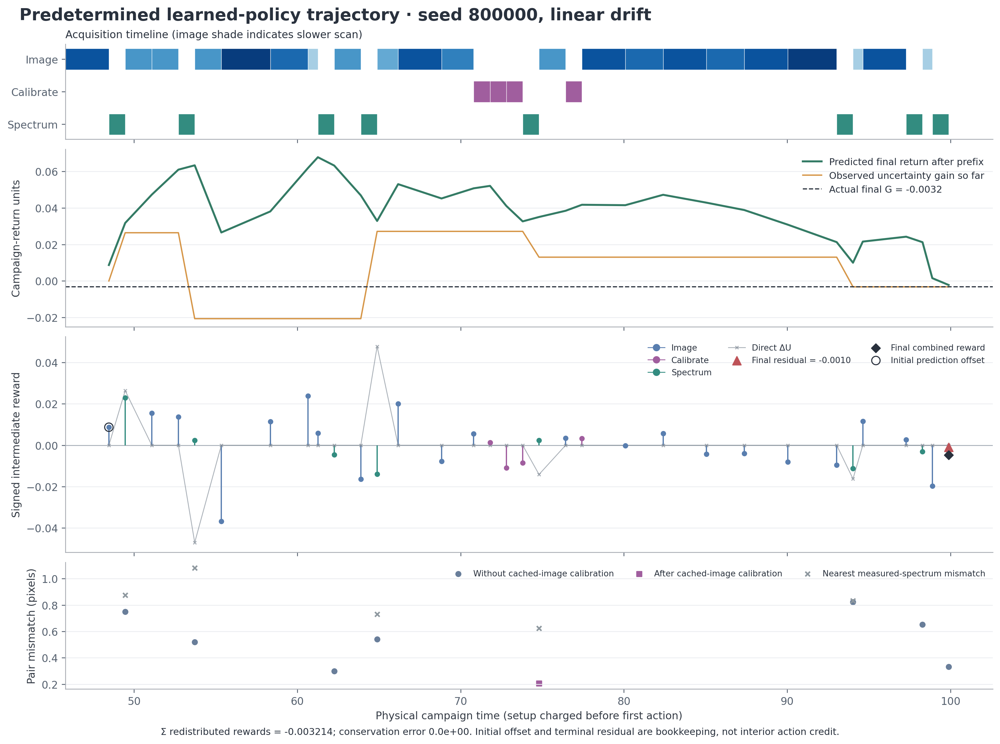

In [9]:
saved = load_checkpoint(PROJECT / 'results/checkpoints/rudder_seed0.pt')
episode = collect_episode(saved['policy'], DATA, CFG, seed=800000,
                          regime='linear', deterministic=False)
credits = predict_and_redistribute(saved['predictor'], episode)
print(f'Actual campaign score: {episode.terminal_score:.8f}')
print(f'Sum of intermediate rewards: {credits.sum():.8f}')
print(f'Terminal prediction correction: {episode.terminal_residual:.8f}')
assert np.isclose(credits.sum(), episode.terminal_score, atol=1e-10)
credit_table = pd.DataFrame([{'step':i+1, 'time':event['time_end'],
    'action':event['kind'], 'tau':event.get('tau'),
    'direct_delta_U':episode.direct_rewards[i],
    'predicted_final_return':episode.prefix_predictions[i],
    'RUDDER_reward':credits[i]} for i,event in enumerate(episode.trace)])
display(credit_table.head(18).round(6))
display(Image(filename=str(PROJECT / 'results/analysis/credit_example_learned.png')))


With $\gamma=\lambda=1$, redistributed return-to-go is $G-g(h_{k-1})$. In this implementation that is a learned history baseline for PPO. It preserves the campaign objective; improved optimization must be demonstrated empirically. This prototype does not claim the canonical RUDDER Q-learning speedup.

The returned values in <code>credits</code> are already the intermediate rewards. No extra reward-design stage is required. The policy still needs exploration and policy optimization to choose actions.


## 7. Retrain or change the setting

The default keeps the supplied recorded results. Set RUN_TRAINING to True to train into a new output directory. Change the budget, seed-pair count, and training length below, or edit Config and LearningConfig in the included source. Changing the scientific objective or observation vector requires fresh training.

In [10]:
RUN_TRAINING = False
NEW_OUTPUT = PROJECT / 'rerun_results'
command = [sys.executable, str(PROJECT / 'run_study.py'),
    '--data', str(PROJECT / 'data/eels_dataset2.npz'),
    '--output', str(NEW_OUTPUT), '--episodes','192', '--warmup','32',
    '--training-seeds','0,1,2', '--eval-seeds','8', '--workers','1',
    '--budget','100', '--seed-pairs','12']
if RUN_TRAINING:
    subprocess.run(command, check=True, cwd=PROJECT)
    subprocess.run([sys.executable,str(PROJECT / 'analyze_results.py'),
                    '--results',str(NEW_OUTPUT)], check=True, cwd=PROJECT)
else:
    print('Recorded study retained. Set RUN_TRAINING=True to regenerate.')
    print(' '.join(command))


Recorded study retained. Set RUN_TRAINING=True to regenerate.
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/bin/python /workspace/scratch/bc230469faef/notebook_validation_final/Microscopy_RUDDER_Project/rudder_microscopy/run_study.py --data /workspace/scratch/bc230469faef/notebook_validation_final/Microscopy_RUDDER_Project/rudder_microscopy/data/eels_dataset2.npz --output /workspace/scratch/bc230469faef/notebook_validation_final/Microscopy_RUDDER_Project/rudder_microscopy/rerun_results --episodes 192 --warmup 32 --training-seeds 0,1,2 --eval-seeds 8 --workers 1 --budget 100 --seed-pairs 12


## 8. Scope and sources

The simulator uses ideal noiseless reactive registration, midpoint image/spectrum representations, a fixed candidate order, and one small measured field. Image edges use reflected padding. Out-of-field spectra return no training pair. Measured-spectrum lookup is discrete. The source map has 33 × 63 centers, so boundary effects are substantial under the inherited 0.4-pixel-per-unit drift.

Held-out centers are interleaved within one specimen and image patches overlap. These results do not establish new-region or new-specimen generalization. The final RF uncertainty objective needs validation before interpreting improved reward as improved scientific discovery.

- [Kalinin's microscopy paper](https://arxiv.org/abs/2611.11609)
- [Original EELS drift and blur notebook](https://github.com/SergeiVKalinin/RL_and_Rewards/blob/main/RL_EELS/0_EELS_RL_Drift_Blur.ipynb)
- [RUDDER: Return Decomposition for Delayed Rewards](https://arxiv.org/abs/1806.07857)

The included USAGE.txt lists every source module and command. The original-data SHA256, exact split, runtime versions, configuration, every evaluation case, trained weights, reward traces and figures are included in the extracted project.
